# Credit scorecard: EDA and model comparison

This notebook explores the Lending Club granting dataset and compares the deployed
WoE scorecard with tree-based challengers. It reuses the package code
(`credit_scorecard_service`) instead of re-implementing it, so everything shown here
is exactly what `cs-train` and the API use.

**Contents**
1. Data overview
2. Vintages and the out-of-time split
3. Numeric features by outcome
4. Categorical features by outcome
5. Information value and feature selection
6. The scorecard points table
7. Score distribution, risk bands and calibration
8. Challengers: ROC and calibration
9. Explaining XGBoost with SHAP, compared with the scorecard
10. Choosing the cutoff
11. Stability over time
12. Conclusions

Prerequisites: `uv sync --extra train --group notebook`, `uv run cs-download`, `uv run cs-train`.

In [1]:
import json
from itertools import pairwise

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr
from sklearn.metrics import roc_curve

from credit_scorecard_service.config import (
    BINNING,
    DECISION_COSTS,
    MODELS_DIR,
    RANDOM_SEED,
    TIME_SPLIT,
)
from credit_scorecard_service.features import (
    CATEGORICAL_FEATURES,
    EMP_LENGTH_VALUES,
    FEATURE_LABELS,
    MODEL_FEATURES,
    NUMERIC_FEATURES,
    TARGET,
    build_features,
)
from credit_scorecard_service.scorecard import Scorecard
from credit_scorecard_service.training import data
from credit_scorecard_service.training.challengers import CANDIDATES, feature_frame
from credit_scorecard_service.training.metrics import calibration_table, classification_metrics

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.4f}".format)

# Validated categorical palette (first three slots pass all-pairs CVD checks).
# The third slot is below 3:1 contrast, so it is always direct-labelled.
S1, S2, S3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#a3a29c", "#e8e7e3", "#fcfcfb"
SHADE = "#efeeea"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_orange", [S1, "#d6d5d0", S2])

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "font.size": 10,
        "text.color": INK,
        "axes.labelcolor": INK_2,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.edgecolor": GRID,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.spines.left": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "xtick.color": INK_2,
        "ytick.color": INK_2,
        "ytick.left": False,
        "lines.linewidth": 2,
        "legend.frameon": False,
    }
)


def pct(ax, axis="y", decimals=0):
    fmt = plt.FuncFormatter(lambda v, _: f"{v:.{decimals}%}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

## 1. Data overview

In [2]:
df = data.load()
splits = data.time_split(df)
champion = Scorecard.load(MODELS_DIR / "champion.json")
report = json.loads((MODELS_DIR / f"metrics-{champion.version}.json").read_text())

print(f"{len(df):,} loans issued {df['issue_d'].min()} to {df['issue_d'].max()}")
print(f"Overall default rate: {df[TARGET].mean():.1%}")
print(f"Missing values in model columns: {int(df.isna().sum().sum())}")
display(df.head())
display(df[["revenue", "dti_n", "loan_amnt", "fico_n"]].describe(percentiles=[0.01, 0.5, 0.99]).T)

1,347,681 loans issued 2007-06 to 2018-12
Overall default rate: 20.0%
Missing values in model columns: 0


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,emp_length,purpose,home_ownership_n,Default
0,70686,2007-06,"70,000.0000",8.8100,5000,772.0000,10+ years,other,MORTGAGE,0
1,72176,2007-06,"110,000.0000",10.0000,2525,712.0000,< 1 year,other,RENT,0
2,72998,2007-06,"12,000.0000",10.0000,1000,697.0000,< 1 year,other,RENT,0
3,73582,2007-06,"180,000.0000",10.0000,3500,687.0000,< 1 year,other,RENT,0
4,74014,2007-06,"32,000.0000",10.0000,6450,687.0000,2 years,other,RENT,0


,count,mean,std,min,1%,50%,99%,max
revenue,"1,347,681.0000","77,369.6832","70,362.9896","1,896.0000","19,000.0000","65,000.0000","260,000.0000","10,999,200.0000"
dti_n,"1,347,681.0000",18.2991,11.1521,0.0000,1.8000,17.6300,38.4800,999.0000
loan_amnt,"1,347,681.0000","14,408.2305","8,715.3474",500.0000,"1,500.0000","12,000.0000","35,000.0000","40,000.0000"
fico_n,"1,347,681.0000",698.1589,31.8487,612.0000,662.0000,692.0000,802.0000,847.5000


The file is already clean: no missing values in any column the model can use, and
about one loan in five defaults. With that imbalance, accuracy is not a useful metric,
so models are compared on **AUC/Gini** (ranking), **KS** (separation) and
**calibration**.

Two values are extreme. `revenue` reaches about $11M, and `dti_n` uses **999** as a
"not available" code. Binning handles both: each one simply falls into the outermost
bin, so nothing needs clipping.

In [3]:
print(f"dti_n == 999: {(df['dti_n'] >= 999).sum():,} loans")
print(f"dti_n > 100 (excluding 999): {((df['dti_n'] > 100) & (df['dti_n'] < 999)).sum():,} loans")

dti_n == 999: 38 loans
dti_n > 100 (excluding 999): 495 loans


## 2. Vintages and the out-of-time split

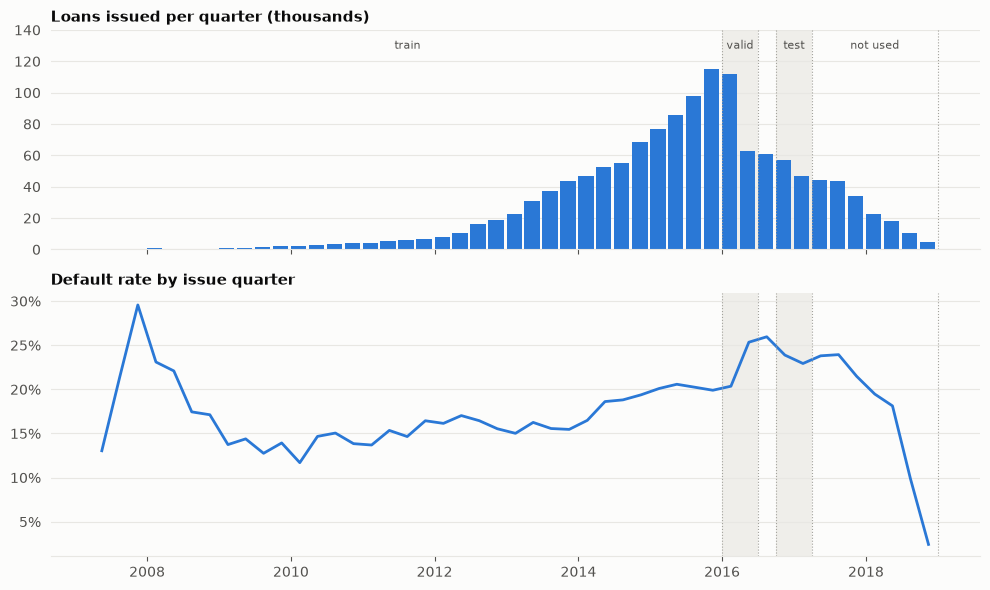

In [4]:
quarterly = df.groupby(df["issue_d"].dt.asfreq("Q")).agg(
    loans=(TARGET, "size"), default_rate=(TARGET, "mean")
)
x = quarterly.index.to_timestamp()


def month_start(m):
    return pd.Period(m, "M").to_timestamp()


def month_end(m):
    return pd.Period(m, "M").to_timestamp(how="end")


regions = [
    ("train", x.min(), month_end(TIME_SPLIT.train_end), None),
    ("valid", month_start(TIME_SPLIT.valid_start), month_end(TIME_SPLIT.valid_end), SHADE),
    ("gap", month_end(TIME_SPLIT.valid_end), month_start(TIME_SPLIT.test_start), None),
    ("test", month_start(TIME_SPLIT.test_start), month_end(TIME_SPLIT.test_end), SHADE),
    ("not used", month_end(TIME_SPLIT.test_end), x.max() + pd.Timedelta(days=92), None),
]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, height_ratios=[1, 1.2])
ax1.bar(x, quarterly["loans"] / 1000, width=78, color=S1, align="edge")
ax1.set_title("Loans issued per quarter (thousands)")
ax2.plot(x + pd.Timedelta(days=45), quarterly["default_rate"], color=S1)
ax2.set_title("Default rate by issue quarter")
pct(ax2)
for ax in (ax1, ax2):
    for _name, start, end, shade in regions:
        if shade:
            ax.axvspan(start, end, color=shade, zorder=0, lw=0)
        ax.axvline(end, color=MUTED, lw=0.8, ls=":")
ax1.set_ylim(0, 140)
for name, start, end, _ in regions:
    if name != "gap":
        ax1.text(start + (end - start) / 2, 128, name, ha="center", color=INK_2, fontsize=8)
fig.tight_layout()

Volume grows sharply until 2016, so the training window is dominated by 2013–2015 loans.

**Why recent vintages are excluded.** The dataset keeps only loans that reached an
outcome. For older vintages that is almost every loan. For 2017–2018 it is mostly
loans that ended *early*: early defaults and early repayments. Their default rate is
therefore an artefact of the snapshot, falling towards 2% at the end of 2018. Training
uses loans up to 2015, model choice uses H1 2016, and the final test uses Oct 2016–Mar
2017 after a three-month gap. The split is by time, never random, because the model
will always score loans issued after the ones it learned from.

In [5]:
display(pd.DataFrame(splits.summary()).T)

,rows,default_rate,from,to
train,829347,0.1846,2007-06,2015-12
valid,174857,0.2215,2016-01,2016-06
test,104170,0.2346,2016-10,2017-03


## 3. Numeric features by outcome

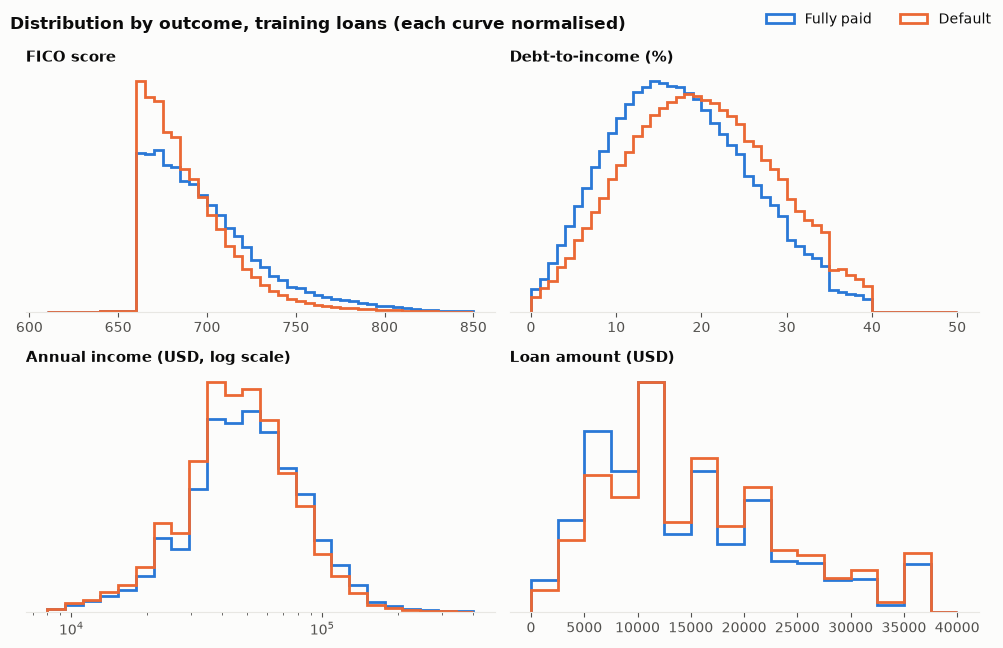

In [6]:
specs = [
    ("fico_n", "FICO score", np.arange(610, 851, 5), False),
    ("dti_n", "Debt-to-income (%)", np.linspace(0, 50, 51), False),
    (
        "revenue",
        "Annual income (USD, log scale)",
        np.logspace(np.log10(8e3), np.log10(4e5), 25),
        True,
    ),
    # Amounts cluster on round numbers; offset edges so each lands inside a bin.
    ("loan_amnt", "Loan amount (USD)", np.arange(0, 40_001, 2_500) - 1, False),
]
train_feats = pd.DataFrame(build_features(splits.train))
y_train = splits.train[TARGET].to_numpy()

fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
for ax, (col, label, bins, log) in zip(axes.flat, specs):
    for outcome, color, name in ((0, S1, "Fully paid"), (1, S2, "Default")):
        ax.hist(
            train_feats.loc[y_train == outcome, col],
            bins=bins,
            density=True,
            histtype="step",
            lw=2,
            color=color,
            label=name,
        )
    ax.set_title(label)
    ax.set_yticks([])
    ax.grid(False)
    if log:
        ax.set_xscale("log")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2)
fig.suptitle(
    "Distribution by outcome, training loans (each curve normalised)",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.tight_layout()

- **FICO** separates the classes visibly: defaults are concentrated below about 700.
  Applicants below about 660 are rare because Lending Club's minimum FICO truncates
  the left tail.
- **Debt-to-income** shifts right for defaults, roughly linearly in risk.
- **Income** and **loan amount** each overlap heavily on their own, but their *ratio*
  carries signal. That is why `loan_to_income` is derived in `features.py` (see
  section 5).

In [7]:
display(train_feats[list(NUMERIC_FEATURES)].corr(method="spearman").round(2))

,revenue,dti_n,loan_amnt,fico_n,loan_to_income
revenue,1.0000,-0.2100,0.5000,0.1200,-0.3200
dti_n,-0.2100,1.0000,0.0500,-0.0400,0.2500
loan_amnt,0.5000,0.0500,1.0000,0.1400,0.6000
fico_n,0.1200,-0.0400,0.1400,1.0000,0.0400
loan_to_income,-0.3200,0.2500,0.6000,0.0400,1.0000


`loan_to_income` has ρ = 0.60 with loan amount and −0.32 with income, and FICO is
nearly independent of everything else (|ρ| ≤ 0.14). No pair is collinear enough to
destabilise a logistic regression. The fit also checks that every coefficient has the
expected sign.

## 4. Categorical features by outcome

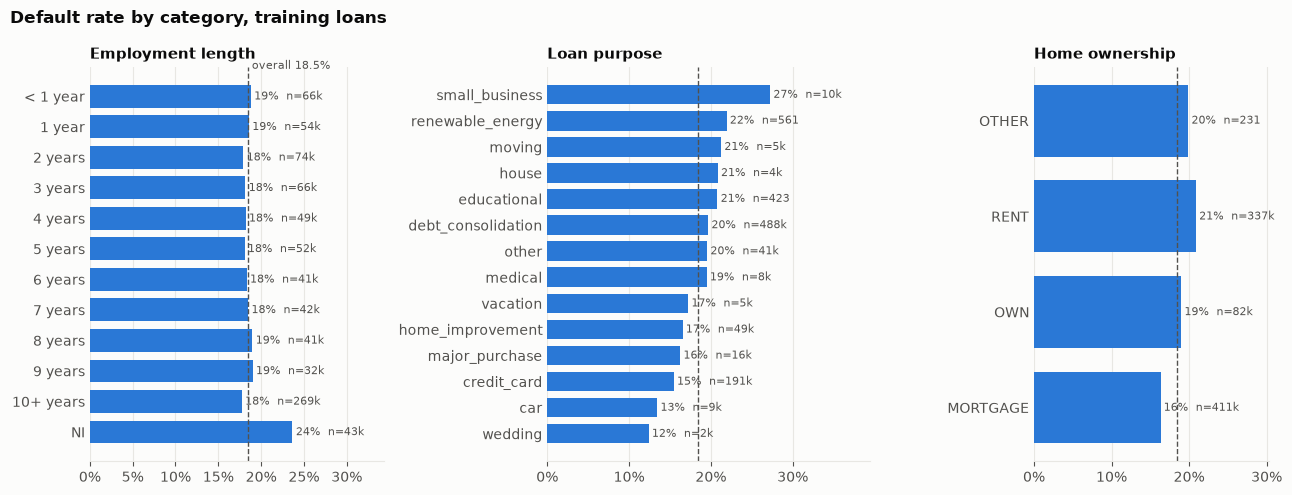

In [8]:
overall = y_train.mean()
orders = {
    "emp_length": list(EMP_LENGTH_VALUES),
    "purpose": None,
    "home_ownership_n": ["MORTGAGE", "OWN", "RENT", "OTHER"],
}
fig, axes = plt.subplots(1, 3, figsize=(13, 5), width_ratios=[1, 1.1, 0.8])
for ax, col in zip(axes, CATEGORICAL_FEATURES):
    g = splits.train.groupby(col)[TARGET].agg(["mean", "size"])
    g = g.loc[orders[col]] if orders[col] else g.sort_values("mean")
    g = g.dropna()
    ax.barh(g.index, g["mean"], color=S1, height=0.75)
    ax.axvline(overall, color=INK_2, lw=1, ls="--")
    for i, (rate, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(
            rate + 0.004,
            i,
            f"{rate:.0%}  n={n / 1000:,.0f}k" if n >= 1000 else f"{rate:.0%}  n={n}",
            va="center",
            fontsize=8,
            color=INK_2,
        )
    ax.set_title(FEATURE_LABELS[col])
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, g["mean"].max() * 1.45)
    pct(ax, "x")
    ax.tick_params(axis="y", length=0)
axes[0].invert_yaxis()
axes[0].text(overall, -0.9, f" overall {overall:.1%}", color=INK_2, fontsize=8)
fig.suptitle("Default rate by category, training loans", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

- **Loan purpose** spans a wide range (small-business loans default far more than
  car or credit-card loans), but the high-risk purposes are small. Weighted by volume,
  the overall signal is modest.
- **Employment length** is nearly flat apart from the "no information" group, which
  is riskier.
- **Renters** default more than homeowners, a small but consistent effect.

## 5. Information value and feature selection

Dropped: {}


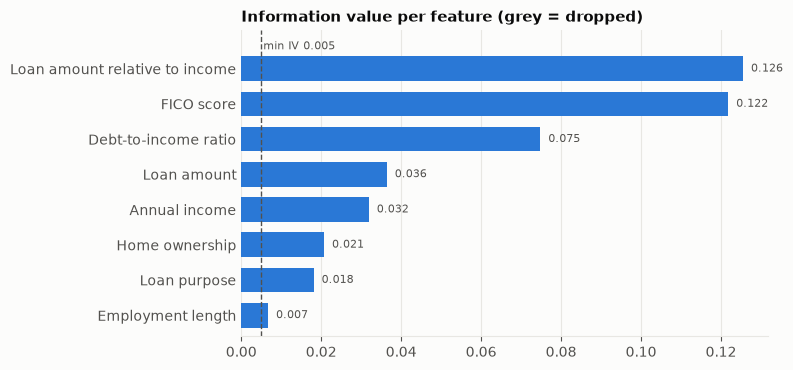

In [9]:
iv = pd.Series(report["information_values"]).sort_values()
kept = set(report["selected_features"])

fig, ax = plt.subplots(figsize=(8, 3.8))
colors = [S1 if f in kept else MUTED for f in iv.index]
ax.barh([FEATURE_LABELS[f] for f in iv.index], iv.values, color=colors, height=0.7)
ax.axvline(BINNING.min_iv, color=INK_2, lw=1, ls="--")
ax.set_ylim(-0.6, len(iv) + 0.1)
ax.text(
    BINNING.min_iv + 0.0005, len(iv) - 0.45, f"min IV {BINNING.min_iv:g}", color=INK_2, fontsize=8
)
for i, (f, v) in enumerate(iv.items()):
    ax.text(
        v + 0.002,
        i,
        f"{v:.3f}" + ("" if f in kept else "  dropped"),
        va="center",
        fontsize=8,
        color=INK_2,
    )
ax.set_title("Information value per feature (grey = dropped)")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
print("Dropped:", report["dropped_features"])

The usual reading of IV: below 0.02 not useful, 0.02–0.1 weak, 0.1–0.3 medium. Only
FICO and loan-to-income are medium. The dataset has no credit-bureau detail
(utilisation, delinquencies, inquiries), so modest discrimination should be expected
from any model, scorecard or not. The derived `loan_to_income` is the single strongest
feature, ahead of FICO.

Purpose (0.018) and employment length (0.007) sit below the conventional 0.02 cutoff,
but the scorecard keeps them: its cutoff is 0.005. `cs-sensitivity` showed that
dropping them costs 0.003 validation AUC, and both get coefficients with the expected
sign.

## 6. The scorecard points table

The deployed artifact (`models/champion.json`) is the whole model. Each bin carries
`−factor · β · WoE` points, and the score is base points plus the sum over features.
Below are the points with the training default rate in each bin.

In [10]:
def fmt_edge(feature, v):
    if feature in ("revenue", "loan_amnt"):
        return f"{v / 1000:.1f}k"
    if feature == "loan_to_income":
        return f"{v:.2f}"
    return f"{v:g}" if feature == "fico_n" else f"{v:.1f}"


def bin_labels(card):
    e = [fmt_edge(card.name, v) for v in card.bins.splits]
    return [f"< {e[0]}"] + [f"{a}–{b}" for a, b in pairwise(e)] + [f"≥ {e[-1]}"]


rows = []
for card in champion.features:
    _, idx = card.bins.apply(train_feats[card.name].to_numpy())
    if card.kind == "numeric":
        bin_names = bin_labels(card)
    else:
        bin_names = [", ".join(group) for group in card.bins.categories]
    for b, (name, points) in enumerate(zip(bin_names, card.bins.points)):
        mask = idx == b
        rows.append(
            {
                "feature": card.name,
                "bin": name,
                "points": round(points, 1),
                "share": mask.mean(),
                "default_rate": y_train[mask].mean() if mask.any() else np.nan,
            }
        )
points_table = pd.DataFrame(rows)
print(
    f"Base points: {champion.base_points:.1f}   score range: "
    f"{champion.score_range[0]:.0f}–{champion.score_range[1]:.0f}   "
    f"(600 points = 50:1 good:bad odds, +{champion.pdo:.0f} points doubles the odds)"
)
display(points_table.style.format({"share": "{:.1%}", "default_rate": "{:.1%}"}).hide(axis="index"))

Base points: 530.0   score range: 479–599   (600 points = 50:1 good:bad odds, +20 points doubles the odds)


feature,bin,points,share,default_rate
revenue,< 37.1k,-1.700000,14.2%,21.8%
revenue,37.1k–45.6k,-1.300000,11.8%,21.0%
revenue,45.6k–50.4k,-0.900000,7.5%,20.3%
revenue,50.4k–60.9k,-0.700000,14.0%,19.9%
revenue,60.9k–70.7k,-0.100000,11.4%,18.7%
revenue,70.7k–75.5k,0.300000,5.3%,17.9%
revenue,75.5k–85.1k,0.600000,8.5%,17.3%
revenue,85.1k–100.2k,1.400000,9.8%,16.0%
revenue,100.2k–127.9k,2.200000,8.7%,14.7%
revenue,≥ 127.9k,3.000000,8.8%,13.5%


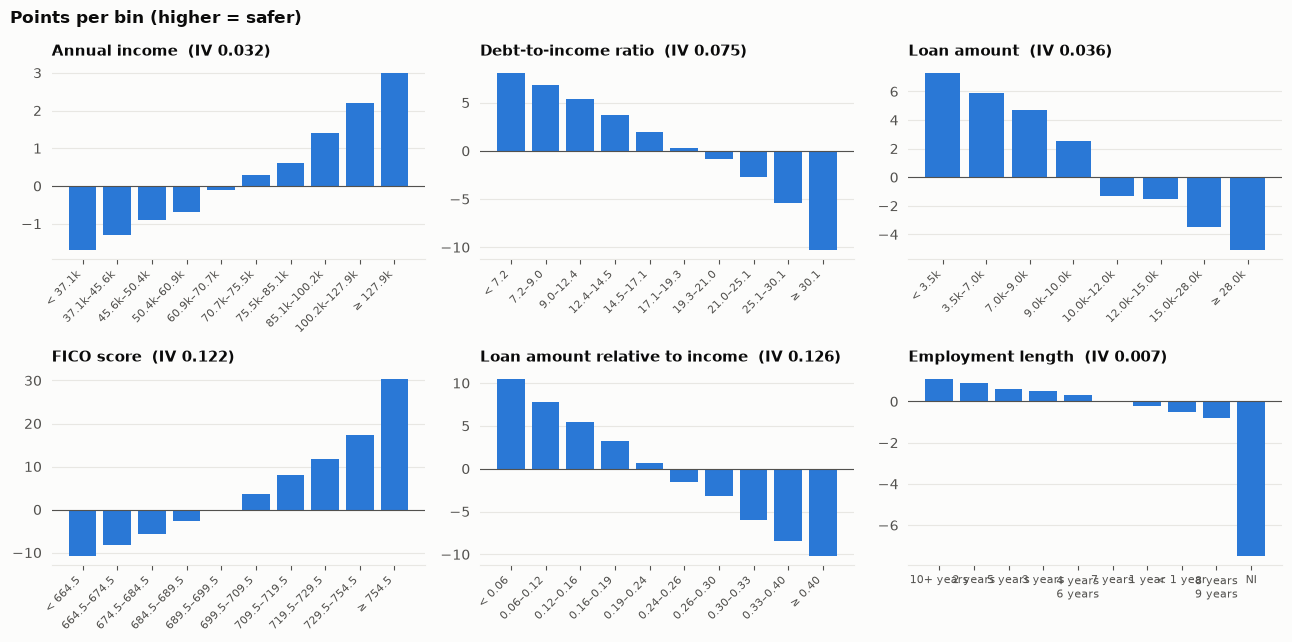

In [11]:
cards = champion.features
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, card in zip(axes.flat, cards):
    sub = points_table[points_table["feature"] == card.name]
    labels = sub["bin"].str.replace(", ", "\n") if card.kind == "categorical" else sub["bin"]
    ax.bar(range(len(sub)), sub["points"], color=S1, width=0.8)
    ax.axhline(0, color=INK_2, lw=0.8)
    ax.set_xticks(
        range(len(sub)),
        labels,
        rotation=45 if card.kind == "numeric" else 0,
        ha="right" if card.kind == "numeric" else "center",
        fontsize=8,
    )
    ax.set_title(f"{FEATURE_LABELS[card.name]}  (IV {card.information_value:.3f})")
for ax in axes.flat[len(cards) :]:
    ax.set_visible(False)
fig.suptitle("Points per bin (higher = safer)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

Every numeric feature gets a monotonic points pattern, enforced by the binning:
higher FICO always earns more points, and higher DTI and loan-to-income always earn
fewer. This is what makes reason codes defensible. An applicant can be told that
improving a given feature can never lower their score.

`revenue` and `loan_amnt` stay in the model alongside their ratio. Income adds only
about 5 points of range, but loan amount still adds about 12 on top of the ratio:
larger loans are riskier even at the same loan-to-income.

## 7. Score distribution, risk bands and calibration (test months)

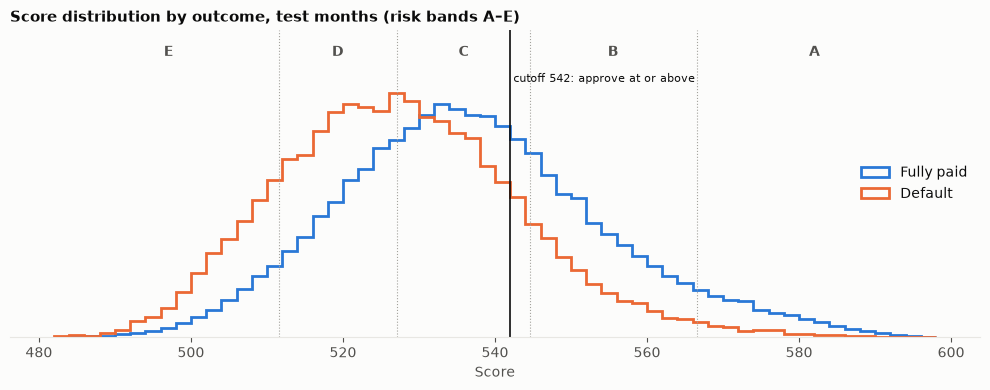

In [12]:
y_test = splits.test[TARGET].to_numpy()
score_test = champion.total_score(splits.test)
pd_sc = champion.score_to_pd(score_test)

fig, ax = plt.subplots(figsize=(10, 4))
bins = np.arange(np.floor(score_test.min()), np.ceil(score_test.max()) + 2, 2)
for outcome, color, name in ((0, S1, "Fully paid"), (1, S2, "Default")):
    ax.hist(
        score_test[y_test == outcome],
        bins=bins,
        density=True,
        histtype="step",
        lw=2,
        color=color,
        label=name,
    )
ax.set_ylim(0, ax.get_ylim()[1] * 1.2)
ax.axvline(champion.cutoff_score, color=INK, lw=1.2)
ax.text(
    champion.cutoff_score + 0.5,
    ax.get_ylim()[1] * 0.86,
    f"cutoff {champion.cutoff_score:.0f}: approve at or above",
    fontsize=8,
    va="top",
)
for band in champion.risk_bands[:-1]:
    ax.axvline(band.min_score, color=MUTED, lw=0.8, ls=":")
uppers = [score_test.max()] + [b.min_score for b in champion.risk_bands[:-1]]
lowers = [b.min_score for b in champion.risk_bands[:-1]] + [score_test.min()]
for band, lo, hi in zip(champion.risk_bands, lowers, uppers):
    ax.text(
        (lo + hi) / 2,
        ax.get_ylim()[1] * 0.95,
        band.name,
        ha="center",
        va="top",
        color=INK_2,
        fontweight="bold",
    )
ax.set_yticks([])
ax.grid(False)
ax.set_xlabel("Score")
ax.set_title("Score distribution by outcome, test months (risk bands A–E)")
ax.legend(loc="center right")
fig.tight_layout()

,share,observed_default_rate,mean_predicted_pd
band,,,
A,5.0%,6.3%,4.6%
B,21.6%,12.9%,9.4%
C,39.2%,21.5%,15.8%
D,25.8%,31.8%,24.1%
E,8.4%,44.4%,34.8%


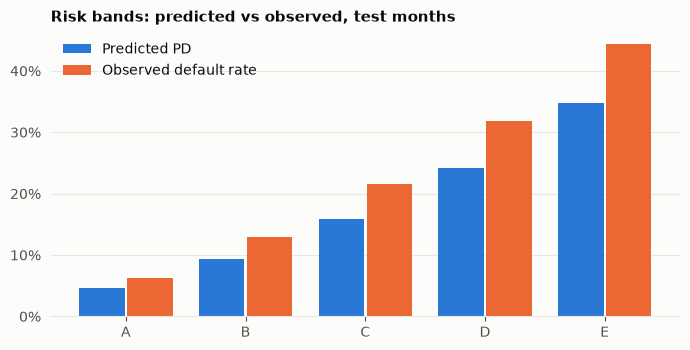

In [13]:
band_of = np.array([champion.risk_band(s) for s in score_test])
bands = (
    pd.DataFrame({"band": band_of, "default": y_test, "pd": pd_sc})
    .groupby("band")
    .agg(
        share=("default", "size"),
        observed_default_rate=("default", "mean"),
        mean_predicted_pd=("pd", "mean"),
    )
)
bands["share"] /= len(y_test)
display(bands.style.format("{:.1%}"))

fig, ax = plt.subplots(figsize=(7, 3.6))
xb = np.arange(len(bands))
ax.bar(xb - 0.2, bands["mean_predicted_pd"], width=0.38, color=S1, label="Predicted PD")
ax.bar(
    xb + 0.2, bands["observed_default_rate"], width=0.38, color=S2, label="Observed default rate"
)
ax.set_xticks(xb, bands.index)
pct(ax)
ax.legend(loc="upper left")
ax.set_title("Risk bands: predicted vs observed, test months")
fig.tight_layout()

The bands **rank correctly**: each band defaults more than the one above it, which is
what a band is for. In absolute terms, though, every band defaults more than predicted
in the test months. The level shifted (section 11), and the PD should be recalibrated
before it is quoted as a probability. That is a retraining-loop task: refit the
intercept on the most recent matured months.

## 8. Challengers: ROC and calibration

Challengers were tuned on the validation months by `cs-train` (grids in
`training/challengers.py`). The comparison below comes from that run. XGBoost, the
strongest challenger, is refitted here with its best parameters for the plots and SHAP.

In [14]:
rows = []
for name, res in report["model_comparison"].items():
    rows.append(
        {
            "model": name,
            **{f"valid_{k}": res["valid"][k] for k in ("auc", "gini", "ks")},
            **{f"test_{k}": res["test"][k] for k in ("auc", "gini", "ks")},
            "params": res.get("params", "WoE binning + logistic regression"),
        }
    )
comparison = pd.DataFrame(rows).set_index("model")
display(comparison)

,valid_auc,valid_gini,valid_ks,test_auc,test_gini,test_ks,params
model,,,,,,,
woe_scorecard,0.6616,0.3231,0.2298,0.6607,0.3214,0.2298,WoE binning + logistic regression
logreg_onehot,0.6635,0.3270,0.2327,0.6628,0.3255,0.2321,{'C': 0.01}
decision_tree,0.6544,0.3088,0.2229,0.6503,0.3005,0.2171,"{'max_depth': 8, 'min_samples_leaf': 500}"
random_forest,0.6643,0.3286,0.2344,0.6651,0.3301,0.2370,"{'max_depth': 12, 'min_samples_leaf': 200}"
xgboost,0.6695,0.3389,0.2405,0.6684,0.3367,0.2395,"{'max_depth': 5, 'learning_rate': 0.05, 'min_c..."


In [15]:
xgb_params = report["model_comparison"]["xgboost"]["params"]
xgb_candidate = next(c for c in CANDIDATES if c.name == "xgboost")
xgb = xgb_candidate.pipeline(**xgb_params).fit(feature_frame(splits.train), y_train)
pd_xgb = xgb.predict_proba(feature_frame(splits.test))[:, 1]

print("Scorecard:", classification_metrics(y_test, pd_sc))
print("XGBoost:  ", classification_metrics(y_test, pd_xgb))
rho = spearmanr(pd_sc, pd_xgb).statistic
approve_n = int(0.3 * len(y_test))
top_sc = set(np.argsort(pd_sc)[:approve_n])
top_xgb = set(np.argsort(pd_xgb)[:approve_n])
print(f"Rank correlation between the two models: {rho:.3f}")
print(f"Overlap of the 30% each model would approve: {len(top_sc & top_xgb) / approve_n:.1%}")

Scorecard: {'auc': 0.6607, 'gini': 0.3214, 'ks': 0.2298, 'mean_pd': 0.1762, 'default_rate': 0.2346}
XGBoost:   {'auc': 0.6684, 'gini': 0.3367, 'ks': 0.2395, 'mean_pd': 0.1787, 'default_rate': 0.2346}
Rank correlation between the two models: 0.932
Overlap of the 30% each model would approve: 83.9%


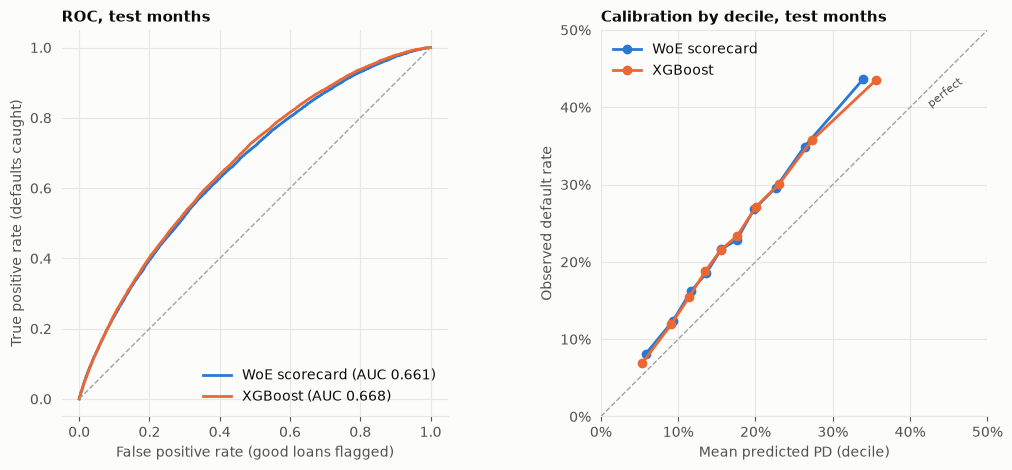

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8))
for p, color, name in ((pd_sc, S1, "WoE scorecard"), (pd_xgb, S2, "XGBoost")):
    fpr, tpr, _ = roc_curve(y_test, p)
    auc = classification_metrics(y_test, p)["auc"]
    ax1.plot(fpr, tpr, color=color, label=f"{name} (AUC {auc:.3f})")
ax1.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
ax1.set_xlabel("False positive rate (good loans flagged)")
ax1.set_ylabel("True positive rate (defaults caught)")
ax1.set_title("ROC, test months")
ax1.legend(loc="lower right")
ax1.set_aspect("equal")
ax1.grid(axis="x")

for p, color, name in ((pd_sc, S1, "WoE scorecard"), (pd_xgb, S2, "XGBoost")):
    cal = pd.DataFrame(calibration_table(y_test, p))
    ax2.plot(cal["predicted_pd"], cal["observed_rate"], color=color, marker="o", ms=6, label=name)
lim = [0, 0.5]
ax2.plot(lim, lim, color=MUTED, lw=1, ls="--")
ax2.text(0.42, 0.40, "perfect", color=INK_2, fontsize=8, rotation=38)
ax2.set_xlim(lim)
ax2.set_ylim(lim)
pct(ax2)
pct(ax2, "x")
ax2.set_xlabel("Mean predicted PD (decile)")
ax2.set_ylabel("Observed default rate")
ax2.set_title("Calibration by decile, test months")
ax2.legend(loc="upper left")
ax2.set_aspect("equal")
ax2.grid(axis="x")
fig.tight_layout()

The two ROC curves almost overlap. XGBoost's edge is under one AUC point, spread
evenly across the curve rather than concentrated where the cutoff sits. Both models
under-predict on the test months to a similar degree. This is a data shift, not a
weakness of either model, so switching to XGBoost would not remove the need for
recalibration.

## 9. Explaining XGBoost with SHAP, compared with the scorecard

SHAP values from `TreeExplainer` are additive contributions to XGBoost's
**log-odds of default**. A scorecard is additive by construction, and each feature's
points convert to the same unit: contribution = −points / factor. That puts both
models on one axis. One-hot SHAP columns are summed back to their original feature.

,WoE scorecard,XGBoost (SHAP)
fico_n,0.3160,0.2390
loan_to_income,0.1750,0.2390
dti_n,0.1510,0.1120
purpose,0.0930,0.1110
loan_amnt,0.1380,0.1090
emp_length,0.0410,0.0400
revenue,0.0460,0.0330
home_ownership_n,0.1040,0.0220


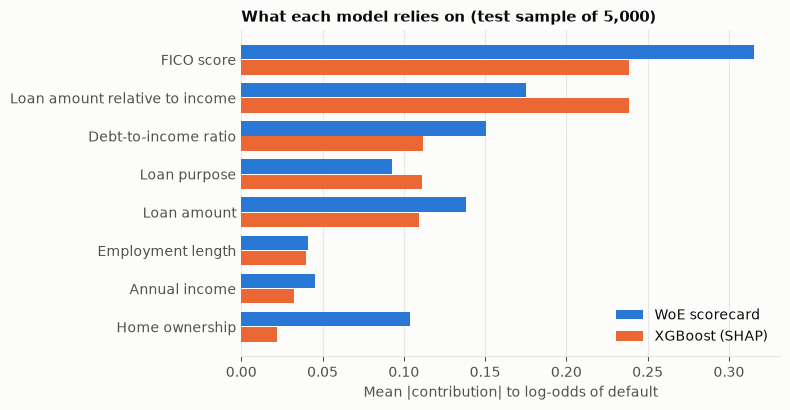

In [17]:
sample = splits.test.sample(5_000, random_state=RANDOM_SEED)
X_sample = feature_frame(sample)
X_enc = xgb["prep"].transform(X_sample)
X_enc = X_enc.toarray() if hasattr(X_enc, "toarray") else X_enc
shap_values = shap.TreeExplainer(xgb["model"]).shap_values(X_enc)


def raw_name(encoded):
    name = encoded.split("__", 1)[1]
    return next((c for c in CATEGORICAL_FEATURES if name.startswith(c + "_")), name)


encoded_names = [raw_name(n) for n in xgb["prep"].get_feature_names_out()]
shap_raw = pd.DataFrame(shap_values, columns=encoded_names).T.groupby(level=0).sum().T
shap_raw = shap_raw[list(MODEL_FEATURES)]

sc_points = pd.DataFrame(champion.points(sample)).reindex(columns=MODEL_FEATURES, fill_value=0.0)
sc_contrib = -sc_points / champion.factor
sc_contrib = sc_contrib - sc_contrib.mean()

importance = pd.DataFrame(
    {
        "WoE scorecard": sc_contrib.abs().mean(),
        "XGBoost (SHAP)": (shap_raw - shap_raw.mean()).abs().mean(),
    }
).sort_values("XGBoost (SHAP)")
display(importance.sort_values("XGBoost (SHAP)", ascending=False).round(3))

fig, ax = plt.subplots(figsize=(8, 4.2))
yy = np.arange(len(importance))
ax.barh(yy + 0.2, importance["WoE scorecard"], height=0.38, color=S1, label="WoE scorecard")
ax.barh(yy - 0.2, importance["XGBoost (SHAP)"], height=0.38, color=S2, label="XGBoost (SHAP)")
ax.set_yticks(yy, [FEATURE_LABELS[f] for f in importance.index])
for i, f in enumerate(importance.index):
    if f not in kept:
        ax.text(0.003, i + 0.2, "not in scorecard", va="center", fontsize=8, color=INK_2)
ax.set_xlabel("Mean |contribution| to log-odds of default")
ax.set_title("What each model relies on (test sample of 5,000)")
ax.legend(loc="lower right")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()

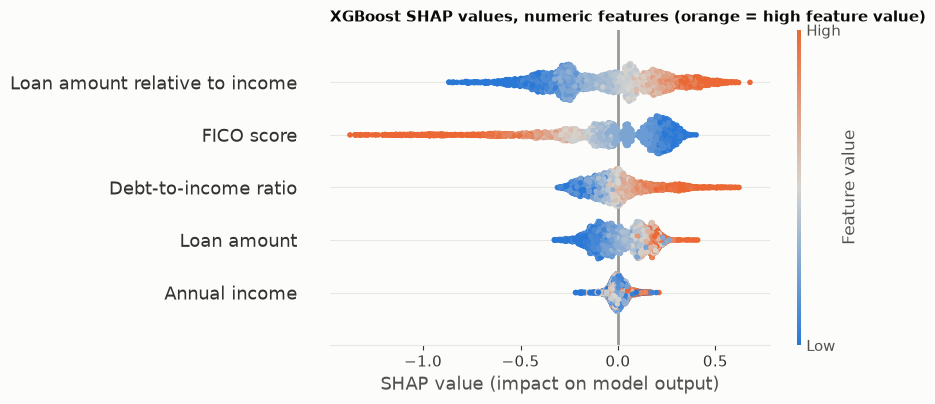

In [18]:
shap.summary_plot(
    shap_raw[list(NUMERIC_FEATURES)].to_numpy(),
    features=X_sample[list(NUMERIC_FEATURES)],
    feature_names=[FEATURE_LABELS[f] for f in NUMERIC_FEATURES],
    cmap=DIVERGING,
    show=False,
    plot_size=(9, 4),
)
plt.gca().set_title("XGBoost SHAP values, numeric features (orange = high feature value)")
plt.gcf().set_facecolor(SURFACE)
plt.show()

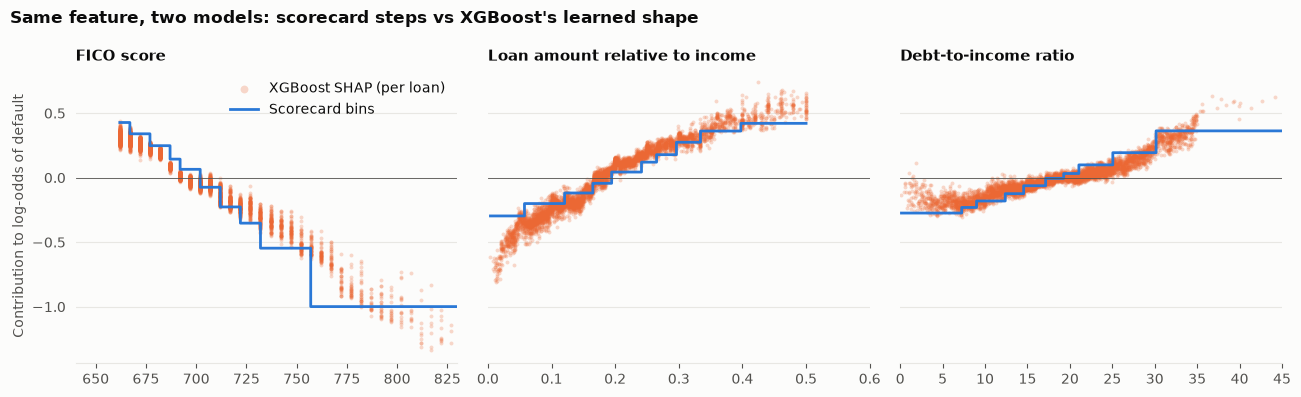

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
ranges = {"fico_n": (640, 830), "loan_to_income": (0, 0.6), "dti_n": (0, 45)}
for ax, (feat, (lo, hi)) in zip(axes, ranges.items()):
    xv = X_sample[feat].to_numpy()
    shap_c = shap_raw[feat] - shap_raw[feat].mean()
    ax.scatter(xv, shap_c, s=8, color=S2, alpha=0.25, lw=0, label="XGBoost SHAP (per loan)")
    order = np.argsort(xv)
    ax.plot(
        xv[order],
        sc_contrib[feat].to_numpy()[order],
        color=S1,
        lw=2,
        drawstyle="steps-post",
        label="Scorecard bins",
    )
    ax.axhline(0, color=INK_2, lw=0.6)
    ax.set_xlim(lo, hi)
    ax.set_title(FEATURE_LABELS[feat])
axes[0].set_ylabel("Contribution to log-odds of default")
axes[0].legend(loc="upper right", markerscale=2)
fig.suptitle(
    "Same feature, two models: scorecard steps vs XGBoost's learned shape",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.tight_layout()

## 10. Choosing the cutoff

{'pd_threshold': 0.1302, 'approval_rate': 0.2887, 'bad_rate_approved': 0.1125, 'cost_per_applicant': 0.6846, 'costs': {'approve_bad': 5.0, 'decline_good': 1.0}}


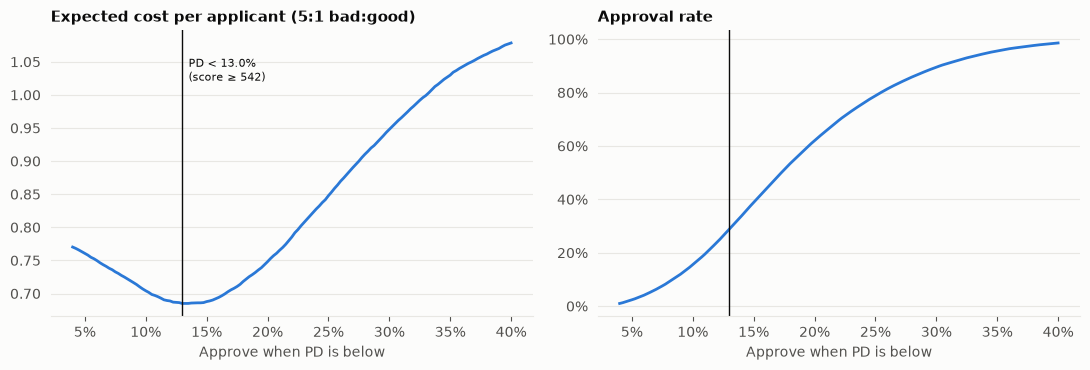

In [20]:
y_valid = splits.valid[TARGET].to_numpy()
pd_valid = champion.predict_pd(splits.valid)
thresholds = np.linspace(0.04, 0.40, 145)
approve = pd_valid[None, :] < thresholds[:, None]
bads_approved = (approve & (y_valid == 1)).sum(axis=1)
goods_declined = (~approve & (y_valid == 0)).sum(axis=1)
cost = (
    DECISION_COSTS.approve_bad * bads_approved + DECISION_COSTS.decline_good * goods_declined
) / len(y_valid)
approval_rate = approve.mean(axis=1)
chosen = report["cutoff"]["pd_threshold"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
ax1.plot(thresholds, cost, color=S1)
ax1.axvline(chosen, color=INK, lw=1)
ax1.text(
    chosen + 0.005,
    cost.max() * 0.98,
    f"PD < {chosen:.1%}\n(score ≥ {champion.cutoff_score:.0f})",
    fontsize=8,
    va="top",
)
ax1.set_title(f"Expected cost per applicant ({DECISION_COSTS.approve_bad:.0f}:1 bad:good)")
ax2.plot(thresholds, approval_rate, color=S1)
ax2.axvline(chosen, color=INK, lw=1)
ax2.set_title("Approval rate")
pct(ax2)
for ax in (ax1, ax2):
    pct(ax, "x")
    ax.set_xlabel("Approve when PD is below")
fig.tight_layout()
print(report["cutoff"])

The cost curve is flat near its minimum, so the exact cutoff matters less than the
cost ratio. A 5:1 ratio approves about 29% of validation applicants, which is strict
by consumer-lending standards, because this model sees only seven fields and the base
default rate is 22%. The ratio is a business input (`DecisionCosts` in `config.py`),
not something the model decides.

## 11. Stability over time

,score,revenue,dti_n,loan_amnt,fico_n,loan_to_income
valid,0.001,0.012,0.021,0.006,0.002,0.005
test,0.011,0.031,0.003,0.022,0.002,0.051


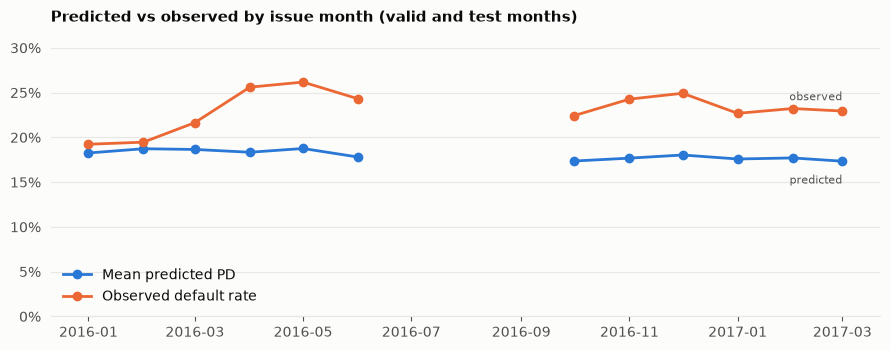

In [21]:
display(pd.DataFrame(report["psi_vs_train"]).T.style.format("{:.3f}"))

recent = pd.concat([splits.valid, splits.test])
monthly = (
    recent.assign(pd_=champion.predict_pd(recent))
    .groupby("issue_d")
    .agg(predicted=("pd_", "mean"), observed=(TARGET, "mean"))
)
# Reindex so the unused gap months break the line instead of being bridged.
monthly = monthly.reindex(pd.period_range(monthly.index.min(), monthly.index.max(), freq="M"))
fig, ax = plt.subplots(figsize=(9, 3.6))
xm = monthly.index.to_timestamp()
ax.plot(xm, monthly["predicted"], color=S1, marker="o", ms=6, label="Mean predicted PD")
ax.plot(xm, monthly["observed"], color=S2, marker="o", ms=6, label="Observed default rate")
ax.text(
    xm[-1], monthly["observed"].iloc[-1] + 0.012, "observed", color=INK_2, fontsize=8, ha="right"
)
ax.text(
    xm[-1], monthly["predicted"].iloc[-1] - 0.025, "predicted", color=INK_2, fontsize=8, ha="right"
)
pct(ax)
ax.set_ylim(0, 0.32)
ax.set_title("Predicted vs observed by issue month (valid and test months)")
ax.legend(loc="lower left")
fig.tight_layout()

PSI rules of thumb: below 0.1 stable, 0.1–0.25 watch, above 0.25 act. The score and
every input are stable (all below 0.06), so the *applicants* look like the training
population. What changed is the *outcome rate*. This is the case PSI cannot catch on
its own, and the reason the retraining loop also tracks AUC and the predicted-versus-
observed gap once outcomes arrive.

## 12. Conclusions

**Data.** 1.35M resolved loans, seven application-time fields, 20% defaults, no
missing values. Because the snapshot keeps only resolved loans, recent vintages are
biased. The model is therefore trained to 2015, tuned on H1 2016 and tested on
Oct 2016–Mar 2017 after a gap. Loans issued after March 2017 are not used.

**Signal.** Most of it sits in three features: loan-to-income (IV 0.126, derived in
`features.py`), FICO (0.122) and debt-to-income (0.075). Purpose (0.018) and
employment length (0.007) are weak but still add 0.003 AUC, so v2 keeps them with an
IV cutoff of 0.005 instead of the conventional 0.02.

**Model comparison (test months).**

| | AUC | Gini | KS |
|---|---|---|---|
| WoE scorecard v2 (champion) | 0.661 | 0.321 | 0.230 |
| WoE scorecard v1 (IV cutoff 0.02) | 0.658 | 0.317 | 0.227 |
| XGBoost | 0.668 | 0.337 | 0.240 |

The models largely agree: rank correlation 0.93, and 84% overlap in the 30% of
applicants each would approve.

**What SHAP adds.** Both models rank FICO, loan-to-income and DTI as their top
numeric drivers, with the same monotonic shapes. XGBoost's learned curves follow the
scorecard's steps closely. With purpose back in the scorecard, the two models give it
similar weight (mean |contribution| 0.093 vs 0.111). XGBoost's remaining lift comes
from two places:
- the tails: FICO above about 760 keeps lowering risk where the top scorecard bin is flat;
- interactions the additive scorecard cannot express.

The scorecard still puts more weight on home ownership (0.104 vs 0.022).

**Decision.** Keep the scorecard as champion. Under one AUC point does not outweigh
points a credit officer can read, monotonic reason codes that are guaranteed to make
sense, and a 10 KB JSON artifact that serves without an ML runtime.

**Calibration is the real issue, not discrimination.** Applicants are stable
(PSI < 0.06), but default rates rose for 2016 vintages and both models under-predict
by about 6 percentage points. Model choice does not fix this. The retraining loop has
to recalibrate on recent matured months and monitor predicted-versus-observed default
rates, not only PSI.

**Next iterations to try.**
1. Allow a finer top FICO bin.
2. Intercept recalibration on the latest matured months.

Keep each change only if validation AUC and calibration both improve.